# SignalProcessing-04 — Le signal dans le canal : la capacité

**Sous-série du hub « Information & calcul » (#27092)**

Les carnets 01 et 02 ont mesuré un signal et l'ont filtré ; le 03 le quantifie.
Celui-ci change de question : le signal doit maintenant **traverser un canal** —
un câble, une fibre, une onde radio — et le canal n'est pas transparent. Il ne
laisse passer qu'une **bande** de fréquences, et il ajoute du **bruit**. Combien
d'information peut-on alors faire passer, de façon fiable, chaque seconde ? La
réponse est une **borne**, la formule de Shannon-Hartley :

$$C = B \log_2\!\left(1 + \frac{S}{N}\right)$$

où $B$ est la bande passante du canal et $S/N$ le rapport signal sur bruit qu'il
laisse à la sortie. Ce carnet **mesure** ces deux grandeurs sur un canal simulé,
puis vérifie ce que la formule prédit — et ce qu'elle ne promet pas.

*Bibliothèque : numpy (`np.fft`, `np.log2`, générateur aléatoire).* · *Sources : Shannon 1948 (BSTJ 27-3 et 27-4) ; Hartley 1928 (BSTJ 7-3).* · **Prev :** [02 — Convolution et filtrage](SignalProcessing-02-Convolution-Et-Filtrage-Python.ipynb), dernier publié — le 03, la quantification, est en PR (#27391)

**Prérequis :** carnets 01 (spectre, FFT) et 02 (filtrage dans le domaine fréquentiel) ;
un décibel vaut $10\log_{10}$ d'un rapport de puissances. · **Durée estimée :**
45 minutes · **Objectifs :** mesurer la puissance d'un bruit filtré et un rapport
signal/bruit en décibels ; calculer la capacité d'un canal et distinguer ses deux
leviers ; comprendre pourquoi élargir la bande ne double pas le débit ; retrouver
la forme de la formule dans le comptage de Hartley.


In [1]:
import math

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline
plt.rcParams['figure.figsize'] = (9, 3)
rng = np.random.default_rng(0)   # le generateur du carnet : la simulation est reproductible

print('numpy', np.__version__, '- generateur initialise a la graine 0')


numpy 2.4.2 - generateur initialise a la graine 0


## §1 — Le canal : une bande passante

Un canal réel n'est pas un fil parfait : il atténue les fréquences éloignées de
celles qu'il est prévu de transporter. Le modèle le plus simple qui en garde
l'essentiel est un **canal idéal de bande** $B$ : gain 1 pour les fréquences
$|f| \le B$, gain 0 au-delà. C'est un filtre, et on le construit comme au carnet
02, dans le domaine fréquentiel.

La méthode est celle du carnet 01 : passer dans le domaine fréquentiel par FFT,
mettre à zéro ce qui sort de la bande, revenir par FFT inverse. Deux sinusoïdes
servent de sondes : l'une dans la bande, l'autre dehors. Elles comptent chacune
un nombre entier de périodes dans la fenêtre, de façon à occuper une seule raie
du spectre — la mesure ne mélange donc pas l'effet du canal à une fuite spectrale.


In [2]:
fs = 10000.0                   # frequence d'echantillonnage (Hz)
N  = 20000                     # 2 s de signal
t  = np.arange(N) / fs
B  = 3000.0                    # bande du canal (Hz) : le canal laisse passer |f| <= B

def limite_bande(u, B, fs):
    """Canal ideal de bande B : gain 1 dans la bande, 0 au-dela."""
    spectre = np.fft.rfft(u)
    spectre[np.fft.rfftfreq(len(u), d=1 / fs) > B] = 0.0
    return np.fft.irfft(spectre, n=len(u))

f_dans = 1000.0                # sonde dans la bande
f_hors = 4000.0                # sonde hors de la bande
x_dans = np.sin(2 * np.pi * f_dans * t)
x_hors = np.sin(2 * np.pi * f_hors * t)

y_dans = limite_bande(x_dans, B, fs)
y_hors = limite_bande(x_hors, B, fs)

ecart_dans  = float(np.max(np.abs(y_dans - x_dans)))
residu_hors = float(np.max(np.abs(y_hors)))
print(f'Bande du canal B                  : {B:.0f} Hz  (Nyquist : {fs / 2:.0f} Hz)')
print(f'Sonde dans la bande ({f_dans:.0f} Hz)    : ecart max a ce qui est emis = {ecart_dans:.1e}')
print(f'Sonde hors de la bande ({f_hors:.0f} Hz) : amplitude max en sortie     = {residu_hors:.1e}')
print(f'La sonde a {f_dans:.0f} Hz passe, intacte : {ecart_dans < 1e-9}')
print(f'La sonde a {f_hors:.0f} Hz est bloquee    : {residu_hors < 1e-9}')


Bande du canal B                  : 3000 Hz  (Nyquist : 5000 Hz)
Sonde dans la bande (1000 Hz)    : ecart max a ce qui est emis = 7.9e-13
Sonde hors de la bande (4000 Hz) : amplitude max en sortie     = 4.0e-12
La sonde a 1000 Hz passe, intacte : True
La sonde a 4000 Hz est bloquee    : True


### Lecture du résultat

Les deux booléens sont `True` : la sonde de 1 kHz ressort identique à ce qui a été
émis, la sonde de 4 kHz ne ressort pas. Les résidus imprimés restent sous le seuil
des deux tests — ils mesurent l'arrondi de la FFT, pas un effet du canal. La bande
fait donc son **tri** : une fréquence de la bande passe, une fréquence hors bande
disparaît.

Un canal est d'abord un **filtre**. Sa largeur $B$ dit combien de fréquences ont le
droit de passer — et, on va le voir, combien de bruit entre avec elles.


## §2 — Puissance, bruit et rapport signal/bruit

Passer la bande ne suffit pas : à la sortie du canal, le signal est noyé dans du
**bruit**. On le modélise comme un bruit blanc gaussien de **densité spectrale de
puissance** $N_0$ : c'est une puissance par hertz, la même à toutes les fréquences.

Un point que l'intuition oublie souvent : le bruit qui gêne n'est pas tout le
bruit qui existe, mais celui que le récepteur **garde**. Un récepteur qui n'écoute
que la bande $B$ ne laisse entrer que la puissance

$$N = N_0 \, B.$$

Le rapport signal sur bruit $S/N$ est un nombre sans dimension. On l'exprime
souvent en **décibels**, $10\log_{10}(S/N)$, parce que les rapports utiles
s'étendent sur plusieurs ordres de grandeur.


Puissance du signal emis S                  : 0.5000
Puissance du bruit garde par la bande N     : 0.0493   (valeur attendue N0*B = 0.0500)
Ecart-type du bruit garde par la bande      : 0.222   (amplitude du signal : 1)
Part de la bande dans la bande de Nyquist   : 0.60
Rapport signal sur bruit S/N                : 10.134   soit 10.06 dB
0 / 10 / 20 / 30 dB valent, en rapport      : 1 / 10 / 100 / 1000


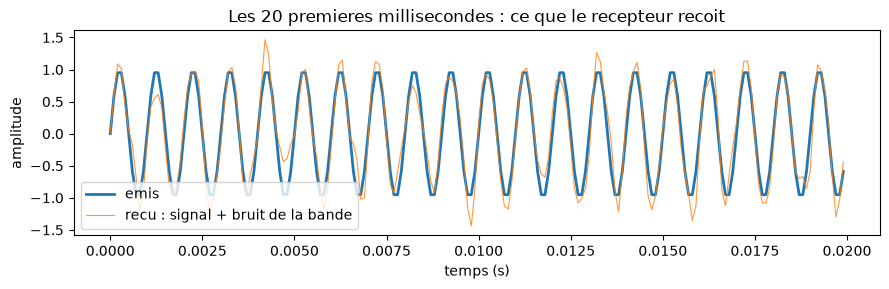

In [3]:
N0    = 1.0 / 60000.0                    # densite spectrale de puissance du bruit
sigma = np.sqrt(N0 * fs / 2.0)           # ecart-type du bruit blanc a l'entree du recepteur
bruit = rng.normal(0.0, sigma, N)
n     = limite_bande(bruit, B, fs)       # la part que le recepteur garde : celle de la bande B
r     = y_dans + n                       # signal recu

def puissance(u):
    """Puissance moyenne d'un signal echantillonne."""
    return float(np.mean(np.square(u)))

def en_db(rapport):
    """Rapport de puissances -> decibels."""
    return 10.0 * np.log10(rapport)

def depuis_db(db):
    """Decibels -> rapport de puissances."""
    return 10.0 ** (db / 10.0)

S   = puissance(y_dans)
Nb  = puissance(n)
snr = S / Nb
print(f'Puissance du signal emis S                  : {S:.4f}')
print(f'Puissance du bruit garde par la bande N     : {Nb:.4f}   (valeur attendue N0*B = {N0 * B:.4f})')
print(f'Ecart-type du bruit garde par la bande      : {np.sqrt(Nb):.3f}   (amplitude du signal : 1)')
print(f'Part de la bande dans la bande de Nyquist   : {B / (fs / 2):.2f}')
print(f'Rapport signal sur bruit S/N                : {snr:.3f}   soit {en_db(snr):.2f} dB')
print('0 / 10 / 20 / 30 dB valent, en rapport      : '
      f'{depuis_db(0):.0f} / {depuis_db(10):.0f} / {depuis_db(20):.0f} / {depuis_db(30):.0f}')

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(t[:200], y_dans[:200], lw=2, label='emis')
ax.plot(t[:200], r[:200], lw=0.8, alpha=0.8, label='recu : signal + bruit de la bande')
ax.set_xlabel('temps (s)')
ax.set_ylabel('amplitude')
ax.set_title('Les 20 premieres millisecondes : ce que le recepteur recoit')
ax.legend()
plt.tight_layout()
plt.show()


### Lecture du résultat

Le signal émis a une puissance de `0.5000` — une sinusoïde d'amplitude 1 — et le
bruit gardé par la bande une puissance de `0.0493`, tout près de la valeur attendue
`0.0500` : l'écart est celui d'un tirage de 20 000 échantillons. Le rapport vaut
donc `10.134`, soit `10.06 dB`. La part de bande `0.60` explique la valeur : le
bruit blanc a pour puissance $\sigma^2 = N_0 f_s/2$ à l'entrée, et le récepteur
n'en garde que la fraction $B/(f_s/2)$.

La figure superpose, sur les 20 premières millisecondes, le signal émis et le
signal reçu : ce dernier est le premier, auquel s'ajoute le bruit de la bande,
d'écart-type `0.222` — un peu moins du quart de l'amplitude du signal.

Deux leviers apparaissent, et ce sont les deux seuls du carnet : **augmenter `S`**
(émettre plus fort, ce qui coûte de la puissance) ou **réduire `N`** (écouter une
bande plus étroite, ce qui coûte des hertz).


## Exercice 1 — Un récepteur plus étroit entend-il mieux ?

Le bruit gardé croît avec la bande. La sonde utile, elle, n'occupe qu'une seule
raie, très en deçà de la bande du canal. Un récepteur qui ne garde que la moitié
de la bande, `B_etroit = 1500` Hz, devrait donc entendre moins de bruit — sans
rien perdre du signal.

**Objectif.** Filtrez le même bruit blanc `bruit` avec cette bande plus étroite,
puis donnez le rapport signal sur bruit obtenu, en décibels, dans `snr_etroit_db`.

**Indice.** `limite_bande`, `puissance` et `en_db` s'appliquent telles quelles ; le
signal utile `y_dans` traverse la bande étroite sans y perdre quoi que ce soit.
Les deux puissances du §2 donnent de quoi prévoir la valeur avant de la mesurer :
$N = N_0 B$ et $S/N = S / (N_0 B)$.


In [4]:
# Exercice 1 — rapport signal sur bruit a la sortie d'un recepteur de bande etroite
B_etroit = 1500.0
snr_etroit_db = None  # TODO etudiant : S/N en dB quand le recepteur ne garde que B_etroit
print('Exercice a completer : snr_etroit_db =', snr_etroit_db)


Exercice a completer : snr_etroit_db = None


## §3 — La capacité du canal

On appelle **capacité** d'un canal le plus grand débit d'information qu'on peut y
transmettre avec un risque d'erreur arbitrairement petit. Pour un canal de bande
$W$ auquel s'ajoute un bruit, Shannon (1948) établit un encadrement de cette
capacité (théorème 18, p. 641) :

$$W \log\frac{P + N_1}{N_1} \;\le\; C \;\le\; W \log\frac{P + N}{N_1}$$

Le cas d'un signal limité en **puissance de crête** est traité à part (théorème 20,
p. 643). Et dans la discussion qui clôt l'article (pp. 644-645), la capacité est
ramenée au seul rapport $S/N$ : Shannon y écrit l'enchaînement

$$C \;\le\; W \log\!\left(1 + \frac{P}{N}\right) \;\le\; W \log\!\left(1 + \frac{S}{N}\right),$$

puis le rapport $C / \bigl(W\log(1 + S/N)\bigr)$ qui tend vers 1 quand $S/N$ tend
vers zéro ; le débit y apparaît sous la forme $W\log\bigl((S+N)/N\bigr)$.

De là vient la forme que l'on appelle aujourd'hui **formule de Shannon-Hartley** :

$$C = B \log_2\!\left(1 + \frac{S}{N}\right) \quad\text{bits par seconde}$$

Le nom rend hommage au comptage de Hartley (1928), dont le §4 montrera la parenté ;
la formule, elle, est de Shannon. Le logarithme est pris en base 2 et l'unité est
le **bit** (BSTJ 27-3, p. 380) : $C/B$ se lit donc comme un nombre de bits par
hertz de bande.


In [5]:
def capacite(B, snr):
    """Capacite d'un canal de bande B (Hz) et de rapport signal sur bruit snr, en bit/s."""
    return B * np.log2(1.0 + snr)

C               = capacite(B, snr)
C_bande_double  = capacite(2.0 * B, snr)
C_signal_double = capacite(B, 2.0 * snr)
print(f'Bande B                                  : {B:.0f} Hz')
print(f'Rapport signal sur bruit                 : {snr:.3f}   ({en_db(snr):.2f} dB)')
print(f'Capacite C = B log2(1 + S/N)             : {C:.0f} bit/s')
print(f'Efficacite spectrale C/B                 : {C / B:.3f} bit/s/Hz')
print(f'Par echantillon, a 2B echantillons/s     : {C / (2 * B):.3f} bit/echantillon')
print(f'Si la bande double, a S/N fixe           : {C_bande_double:.0f} bit/s   soit x{C_bande_double / C:.2f}')
print(f'Si la puissance du signal double         : {C_signal_double:.0f} bit/s   soit x{C_signal_double / C:.2f}')


Bande B                                  : 3000 Hz
Rapport signal sur bruit                 : 10.134   (10.06 dB)
Capacite C = B log2(1 + S/N)             : 10431 bit/s
Efficacite spectrale C/B                 : 3.477 bit/s/Hz
Par echantillon, a 2B echantillons/s     : 1.738 bit/echantillon
Si la bande double, a S/N fixe           : 20862 bit/s   soit x2.00
Si la puissance du signal double         : 13232 bit/s   soit x1.27


### Lecture du résultat

Avec `B = 3000` Hz et un rapport de `10.134`, la formule donne `10431` bit/s, soit
`3.477` bit/s par hertz de bande. Lu autrement : à `2B` échantillons par seconde,
cela fait `1.738` bit par échantillon — **plus d'un bit par échantillon**. C'est le
pont vers le §4 : un échantillon peut porter plusieurs bits, à condition que le
rapport signal sur bruit laisse distinguer plusieurs niveaux.

Les deux dernières lignes séparent les deux leviers. Doubler la bande à rapport
fixé double la capacité (`x2.00`) ; doubler la puissance du signal ne la multiplie
que par `x1.27`. La bande entre **linéairement**, la puissance par un
**logarithme** — et l'écart entre ces deux multiplicateurs est la raison pour
laquelle on se bat pour des hertz.


### Les deux leviers, et leur différence de nature

La formule contient deux grandeurs qu'on peut augmenter : la bande $B$ et le
rapport $S/N$. Ils ne se valent pas. À $S/N$ **fixé**, la capacité est
proportionnelle à $B$ : élargir la bande double la capacité. Mais un canal réel
n'offre pas $S/N$ gratuitement quand on l'élargit : le bruit **entre avec la
bande**, $N = N_0 B$, donc $S/N$ baisse quand $B$ monte.

Les deux situations se tracent sur la même figure, en échelle logarithmique. La
seconde devrait plafonner : c'est ce que la figure va montrer, et ce que la
capacité du canal interdit de franchir.


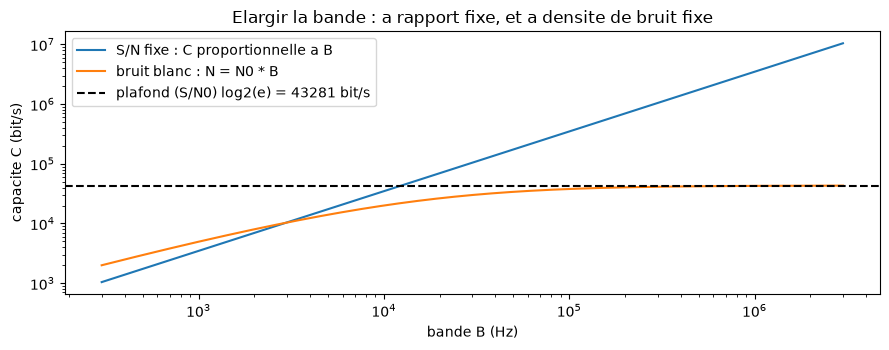

B x1    =      3000 Hz | S/N fixe :      10431 bit/s | bruit blanc (S/N = 10.000) :     10378 bit/s
B x10   =     30000 Hz | S/N fixe :     104309 bit/s | bruit blanc (S/N =  1.000) :     30000 bit/s
B x100  =    300000 Hz | S/N fixe :    1043087 bit/s | bruit blanc (S/N =  0.100) :     41251 bit/s
Plafond quand B tend vers l'infini : 43281 bit/s


In [6]:
plage         = np.geomspace(300.0, 3.0e6, 400)
C_snr_fixe    = capacite(plage, snr)                # le rapport S/N est impose
C_bruit_blanc = capacite(plage, S / (N0 * plage))   # le bruit entre avec la bande : N = N0*B
plafond       = (S / N0) * np.log2(np.e)

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.loglog(plage, C_snr_fixe,    label='S/N fixe : C proportionnelle a B')
ax.loglog(plage, C_bruit_blanc, label='bruit blanc : N = N0 * B')
ax.axhline(plafond, ls='--', c='k', label=f'plafond (S/N0) log2(e) = {plafond:.0f} bit/s')
ax.set_xlabel('bande B (Hz)')
ax.set_ylabel('capacite C (bit/s)')
ax.set_title('Elargir la bande : a rapport fixe, et a densite de bruit fixe')
ax.legend()
plt.tight_layout()
plt.show()

for k in (1, 10, 100):
    Bk = B * k
    print(f'B x{k:<4} = {Bk:>9.0f} Hz | S/N fixe : {capacite(Bk, snr):>10.0f} bit/s '
          f'| bruit blanc (S/N = {S / (N0 * Bk):6.3f}) : {capacite(Bk, S / (N0 * Bk)):>9.0f} bit/s')
print(f'Plafond quand B tend vers l\'infini : {plafond:.0f} bit/s')


### Lecture du résultat

Les trois lignes séparent deux situations que l'on confond souvent. À rapport
**fixé**, la capacité suit la bande exactement : `10431`, `104309`, `1043087`
bit/s pour une bande multipliée par 1, 10, 100. À **densité de bruit fixée**, le
rapport signal sur bruit tombe de `10.000` à `1.000` puis à `0.100`, et la capacité
ne monte qu'à `30000` puis `41251` bit/s : dix fois plus de bande donnent moins de
trois fois plus de capacité, cent fois plus de bande moins de quatre fois plus.

La figure montre la même chose sur quatre décennies : la courbe « S/N fixe » y est
une droite de pente 1 — la proportionnalité — tandis que la courbe « bruit blanc »
s'infléchit et vient se coller sous l'asymptote pointillée, `43281` bit/s. C'est le
plafond $(S/N_0)\log_2 e$ : quand $B$ grandit, $S/N$ tend vers zéro et
$\log_2(1 + S/N) \approx (S/N)\log_2 e$, si bien que le produit $B \cdot (S/N)$
reste borné par $S/N_0$.

Élargir la bande achète donc de moins en moins de capacité, et la bande seule ne
crée pas de débit. Le levier qui reste est la puissance, et il n'agit que par un
logarithme : c'est là toute l'économie de la formule.


## Exercice 2 — La ligne téléphonique

Une ligne téléphonique offre `B = 3100` Hz avec un rapport signal sur bruit de
`40 dB`. Calculez :

1. sa capacité, en bit/s ;
2. la capacité obtenue en doublant la bande (`6200` Hz) à **même densité de bruit**
   $N_0$ — attention, le rapport $S/N$ n'y est plus 40 dB ;
3. le rapport signal sur bruit (en décibels) qu'il faudrait, à bande fixe, pour
   **doubler** la capacité de la question 1.

**Indice.** `depuis_db` convertit un rapport exprimé en décibels, `capacite` prend
un rapport linéaire. Pour la question 2, partez de $S/N = S/(N_0 B)$ : doubler $B$
divise le rapport par deux. Pour la question 3, isolez $S/N$ dans
$B\log_2(1 + S/N) = 2C$.


In [7]:
# Exercice 2 — la ligne telephonique
B_tel, snr_tel_db = 3100.0, 40.0
C_tel              = None  # TODO etudiant : capacite de la ligne, en bit/s
C_tel_bande_double = None  # TODO etudiant : capacite a 2 x B_tel, a densite de bruit N0 constante
snr_double_db      = None  # TODO etudiant : S/N en dB pour doubler C_tel a bande fixe
print('Exercice a completer :', C_tel, C_tel_bande_double, snr_double_db)


Exercice a completer : None None None


## §4 — D'où vient cette forme ? Le comptage de Hartley

Vingt ans avant Shannon, Hartley (1928) comptait déjà l'information d'une
transmission : `n` symboles successifs, chacun choisi parmi `s` valeurs
distinguables, en portent `n log s` (équation 11, p. 542). Et le nombre de valeurs
n'est pas libre : il faut que le récepteur puisse les distinguer sans se tromper.
C'est une condition sur leur **écart**, imposée par le bruit (p. 544) — non sur
leur seul nombre.

Le pont avec le §3 se fait en deux pas. Un canal de bande $B$ transporte `2B`
échantillons par seconde (le taux critique du carnet 01). Et si l'espacement des
niveaux est proportionnel au bruit, leur nombre `s` est proportionnel à
$\sqrt{S/N}$, puisque la puissance moyenne croît comme le carré de l'amplitude.
Le débit du comptage vaut alors

$$2B \log_2 s \;=\; B \log_2 s^2 \;\propto\; B \log_2\!\left(\frac{S}{N}\right),$$

et la forme de la formule de Shannon apparaît déjà, au `1` près.


In [8]:
def debit_hartley(B, niveaux):
    """Debit du comptage de Hartley : 2B echantillons/s, chacun parmi `niveaux` valeurs (bit/s)."""
    return 2.0 * B * np.log2(niveaux)

def puissances_pam(M, A):
    """Puissance moyenne et pas d'une transmission a M niveaux equirepartis dans [-A, A]."""
    niveaux = np.linspace(-A, A, M)
    return float(np.mean(niveaux ** 2)), 2.0 * A / (M - 1)

s_algebrique = float(np.sqrt(1.0 + snr))
print(f's = racine carree de (1 + S/N)        : {s_algebrique:.3f} niveaux')
print(f'Debit du comptage 2B log2(s)          : {debit_hartley(B, s_algebrique):.0f} bit/s')
print(f'Capacite          B log2(1 + S/N)     : {C:.0f} bit/s   (meme valeur : le 2 et le carre se compensent)')

A = 1.0
print(f'Transmission a M niveaux equirepartis dans [-{A:.0f}, {A:.0f}] :')
for M in (2, 4, 8, 16):
    S_pam, pas = puissances_pam(M, A)
    print(f'  M = {M:>2} : pas = {pas:.3f}, puissance moyenne = {S_pam:.3f}, debit = {debit_hartley(B, M):.0f} bit/s')


s = racine carree de (1 + S/N)        : 3.337 niveaux
Debit du comptage 2B log2(s)          : 10431 bit/s
Capacite          B log2(1 + S/N)     : 10431 bit/s   (meme valeur : le 2 et le carre se compensent)
Transmission a M niveaux equirepartis dans [-1, 1] :
  M =  2 : pas = 2.000, puissance moyenne = 1.000, debit = 6000 bit/s
  M =  4 : pas = 0.667, puissance moyenne = 0.556, debit = 12000 bit/s
  M =  8 : pas = 0.286, puissance moyenne = 0.429, debit = 18000 bit/s
  M = 16 : pas = 0.133, puissance moyenne = 0.378, debit = 24000 bit/s


### Lecture du résultat

La première ligne fait le lien entre les deux comptages : `s = 3.337` niveaux, et
le débit `2B log2(s)` vaut `10431` bit/s — exactement la capacité `B log2(1 + S/N)`
imprimée au §3, puisque $s^2 = 1 + S/N$. Le facteur `2` de l'échantillonnage et le
carré de l'espacement se compensent, comme annoncé.

La table montre l'autre face de la pièce. À amplitude de crête fixée, le pas
rétrécit quand on ajoute des niveaux — de `2.000` pour deux niveaux à `0.133` pour
seize — et la puissance moyenne **diminue** en même temps, de `1.000` à `0.378`.
Les débits de `6000` à `24000` bit/s sont donc des maxima conditionnels : ils
supposent les niveaux distinguables, et aucun bruit n'est encore entré dans cette
table. C'est le bruit qui décide combien de niveaux tiennent réellement.


### Combien de niveaux un bruit donné laisse-t-il tenir ?

Le comptage suppose les niveaux distinguables. Un bruit gaussien d'écart-type
$\sigma$ fixe la limite : pour qu'un symbole soit mal reçu, il faut que le bruit
déplace la valeur reçue au-delà de la moitié du pas $d$ qui sépare deux niveaux.
La probabilité correspondante est donnée par la **queue gaussienne**,
$Q(x) = \frac{1}{2}\operatorname{erfc}(x/\sqrt{2})$. En inversant cette relation,
on obtient le pas minimal pour un taux d'erreur visé, donc le nombre de niveaux
qui tiennent entre $-A$ et $A$ — et le débit du comptage, à comparer à la capacité
de Shannon pour le même signal et le même bruit.


In [9]:
def q_gauss(x):
    """Queue gaussienne Q(x) : probabilite qu'une variable normale centree reduite depasse x."""
    return 0.5 * math.erfc(x / math.sqrt(2.0))

def x_pour_erreur(taux):
    """x tel que 2 Q(x) = taux. Bisection sur [0, 10] : la queue est decroissante."""
    bas, haut = 0.0, 10.0
    for _ in range(80):
        milieu = 0.5 * (bas + haut)
        if 2.0 * q_gauss(milieu) > taux:
            bas = milieu
        else:
            haut = milieu
    return 0.5 * (bas + haut)

sigma_lien = 0.05
print(f'Lien a niveaux : amplitude de crete A = {A:.0f}, bruit sigma = {sigma_lien}')
print(f'{"erreur cible":>13} {"pas/sigma":>10} {"M":>3} {"debit (x B)":>11} {"S/N (dB)":>9} {"capacite (x B)":>14} {"debit/capacite":>15}')
for taux in (1e-2, 1e-3, 1e-5, 1e-7):
    x_req  = x_pour_erreur(taux)
    M      = int(np.floor(A / (sigma_lien * x_req))) + 1     # pas minimal 2*sigma*x_req entre -A et A
    S_pam, pas = puissances_pam(M, A)
    snr_pam = S_pam / sigma_lien ** 2
    debit_par_hz = debit_hartley(1.0, M)
    cap_par_hz   = np.log2(1.0 + snr_pam)
    print(f'{taux:>13.0e} {pas / sigma_lien:>10.2f} {M:>3} {debit_par_hz:>11.3f} '
          f'{en_db(snr_pam):>6.1f} dB {cap_par_hz:>14.3f} {debit_par_hz / cap_par_hz:>15.2f}')


Lien a niveaux : amplitude de crete A = 1, bruit sigma = 0.05
 erreur cible  pas/sigma   M debit (x B)  S/N (dB) capacite (x B)  debit/capacite
        1e-02       5.71   8       6.000   22.3 dB          7.430            0.81
        1e-03       6.67   7       5.615   22.5 dB          7.482            0.75
        1e-05      10.00   5       4.644   23.0 dB          7.651            0.61
        1e-07      13.33   4       4.000   23.5 dB          7.802            0.51


### Lecture du résultat

Chaque ligne répond à la question « combien de niveaux tiennent pour cette
exigence d'erreur ? ». Plus l'erreur visée est rare, plus le pas doit être large
devant le bruit — `5.71` fois $\sigma$ pour `1e-02`, `13.33` fois pour `1e-07` —
et moins il tient de niveaux : `8`, puis `7`, `5`, `4`. Le débit du comptage suit
la même pente : `6.000`, `5.615`, `4.644`, `4.000` bits par seconde et par hertz
de bande.

La colonne suivante est la plus instructive. La capacité, calculée pour le **même
signal et le même bruit**, ne baisse pas : elle monte légèrement, de `7.430` à
`7.802` bit/s/Hz, parce que les jeux de niveaux plus petits ont une puissance
moyenne un peu plus forte — la table du paragraphe précédent le montrait déjà.
Le rapport `debit/capacite` descend donc de `0.81` à `0.51`. Exiger une erreur
plus rare **coûte du débit** quand on ne code pas, alors que la capacité n'a pas
bougé : l'écart entre les deux colonnes est ce que le codage de canal doit
reconquérir.


### Vérifier la queue gaussienne par le simulé

La dernière ligne du tableau n'est pas une approximation gratuite : elle se mesure.
On transmet un million de symboles à `M = 8` niveaux dans $[-1, 1]$, on décide au
niveau le plus proche, et on compte les erreurs. La formule
$\frac{2(M-1)}{M}\,Q\!\left(\frac{d}{2\sigma}\right)$ donne le taux attendu — le
facteur $\frac{2(M-1)}{M}$ tient compte des deux niveaux extrêmes, qui ne peuvent
être confondus que d'un seul côté.


In [10]:
def taux_erreur_pam(M, A, sigma, n=1000000, generateur=None):
    """Taux d'erreur simule d'une transmission a M niveaux dans [-A, A], decision au niveau le plus proche."""
    pas     = 2.0 * A / (M - 1)
    indices = generateur.integers(0, M, n)                 # les niveaux emis, par leur indice
    emis    = -A + indices * pas
    recus   = emis + sigma * generateur.standard_normal(n)
    decides = np.clip(np.rint((recus + A) / pas), 0, M - 1)  # indices decides, bornes a [0, M-1]
    return float(np.mean(decides != indices))               # erreur = indice decide != indice emis

def te_theorique(M, pas, sigma):
    """Taux d'erreur attendu d'une transmission a M niveaux : 2 (M-1)/M Q(pas / (2 sigma))."""
    return 2.0 * (M - 1) / M * q_gauss(pas / (2.0 * sigma))

M_essai   = 8
pas_essai = 2.0 * A / (M_essai - 1)
te_mesure  = taux_erreur_pam(M_essai, A, sigma_lien, generateur=np.random.default_rng(1))
te_attendu = te_theorique(M_essai, pas_essai, sigma_lien)
print(f'M = {M_essai} niveaux dans [-{A:.0f}, {A:.0f}], pas = {pas_essai:.4f}, sigma = {sigma_lien}, 1e6 symboles')
print(f'taux d\'erreur simule  : {te_mesure:.2e}')
print(f'taux d\'erreur attendu : {te_attendu:.2e}')
print(f'rapport simule / attendu : {te_mesure / te_attendu:.2f}')


M = 8 niveaux dans [-1, 1], pas = 0.2857, sigma = 0.05, 1e6 symboles
taux d'erreur simule  : 3.71e-03
taux d'erreur attendu : 3.74e-03
rapport simule / attendu : 0.99


### Lecture du résultat

Sur un million de symboles à `8` niveaux, le taux d'erreur simulé vaut `3.71e-03`
et le taux attendu `3.74e-03` : rapport `0.99`. La queue gaussienne n'était donc
pas une commodité de calcul — le modèle du §4 rend compte de ce que fait vraiment
un détecteur qui décide au niveau le plus proche.

Ce point — `8` niveaux, pas de `0.2857`, bruit de `0.05` — est celui de la
première ligne du tableau, et le taux mesuré y reste sous la cible `1e-02` : le
nombre de niveaux y a été arrondi vers le bas, donc le pas retenu est un peu plus
large que le minimum, et la marge d'erreur avec lui. La mesure et le comptage se
confirment l'un l'autre.


## Exercice 3 — Plus de puissance pour le même bruit

Le tableau du §4 a été calculé pour une amplitude de crête `A = 1`. Prenez
maintenant `A_ex3 = 2`, à même bruit `sigma = 0.05`, et regardez la colonne
« debit/capacite » à un taux d'erreur visé de $10^{-3}$.

**Objectif.** Donnez `M_ex3`, le nombre de niveaux qui tiennent à ce taux d'erreur,
et `ratio_ex3`, le rapport entre le débit du comptage et la capacité de Shannon
pour ce même signal. Répondez à la question : gagner 6 dB de puissance rapproche-
t-il le débit sans codage de la capacité ?

**Indice.** Le nombre de niveaux dépend de $A/(\sigma x)$ ; la puissance moyenne
d'un jeu de `M` niveaux équirepartis croît comme $A^2$. `x_pour_erreur`,
`puissances_pam` et `debit_hartley` font le reste.


In [11]:
# Exercice 3 — plus de puissance pour le meme bruit
A_ex3            = 2.0
taux_ex3         = 1e-3
M_ex3            = None  # TODO etudiant : nombre de niveaux qui tiennent a ce taux, pour A_ex3
ratio_ex3        = None  # TODO etudiant : debit du comptage / capacite de Shannon, par hertz de bande
print('Exercice a completer : M_ex3 =', M_ex3, ' ratio_ex3 =', ratio_ex3)


Exercice a completer : M_ex3 = None  ratio_ex3 = None


## Exercice 4 — La capacité quand le signal devient faible

La limite de Shannon citée au §3 dit que $C / \bigl(B \log_2(1 + S/N)\bigr)$ tend
vers 1 quand $S/N$ tend vers zéro. Cette limite a une conséquence utile : pour un
signal faible devant le bruit, la capacité devient **linéaire en puissance**,
$C \approx B \cdot (S/N) \cdot \log_2 e$.

**Objectif.** Calculez `ratios_limite`, la liste des valeurs de
$C / \bigl(B \cdot (S/N) \cdot \log_2 e\bigr)$ pour les rapports `rapports`, et
dites à partir de quel ordre de grandeur l'approximation linéaire est fidèle à 1 %.

**Indice.** `capacite` prend un rapport linéaire ; $\log_2 e = 1/\ln 2$. La liste
`rapports` contient un contrôle à $S/N = 10$, où l'approximation ne doit **pas**
tenir, et trois rapports petits. Une compréhension de liste suffit.


In [12]:
# Exercice 4 — la capacite quand le rapport signal sur bruit devient petit
rapports      = [10.0, 1e-2, 1e-4, 1e-6]
ratios_limite = None  # TODO etudiant : [C / (B * snr * log2(e)) pour chaque rapport]
print('Exercice a completer : ratios_limite =', ratios_limite)


Exercice a completer : ratios_limite = None


## Ce que la capacité dit — et ce qu'elle ne dit pas

La capacité est une **borne**, pas un mode d'emploi. Elle dit quel débit fiable
est possible sur un canal donné ; elle ne dit pas comment l'atteindre. Le §4 en
donne la mesure concrète : à mesure qu'on exige une erreur plus rare, une
transmission à niveaux **sans codage** s'éloigne de la capacité, alors que la
capacité elle-même, elle, ne baisse pas. Ce qui comble l'écart s'appelle **codage
de canal** — un territoire voisin, celui de la série InformationTheory (#27077) :
la capacité y est calculée pour un canal binaire symétrique, et le code de Hamming
y corrige des erreurs sur un canal discret. Compresser, symétriquement, est le
versant **source** — celui de la série Compression.

| Grandeur | Symbole | Ce qu'elle mesure | Où ce carnet la calcule |
|---|---|---|---|
| bande du canal | $B$ | les fréquences que le canal laisse passer | §1 |
| puissance du bruit reçu | $N = N_0 B$ | le bruit que la bande laisse entrer | §2 |
| rapport signal sur bruit | $S/N$ | la marge du signal sur le bruit, en dB | §2 |
| capacité | $C = B \log_2(1 + S/N)$ | le débit fiable maximal | §3 |
| plafond à bande croissante | $(S/N_0)\log_2 e$ | la limite d'un élargissement de bande | §3 |
| niveaux distinguables | $s$ | ce que le bruit laisse distinguer | §4 |
| débit sans codage | $2B \log_2 s$ | ce qu'on obtient sans code correcteur | §4 |

Les carnets précédents ont **préparé** ces grandeurs : la FFT lit la bande (01), le
filtre la fixe (02), la quantification ajoute son propre plancher de bruit (03). La
capacité est la façon dont la théorie de l'information les réunit en un seul
nombre.


## À retenir

- **Un canal est d'abord un filtre.** Sa bande `B` laisse passer les fréquences
  qu'elle contient et rien d'autre ; le bruit qui entre avec elles a une puissance
  proportionnelle à `B` quand sa densité est fixée (§1, §2).
- **La capacité se compte en bits par seconde** : `C = B log2(1 + S/N)`. Avec
  `B = 3000` Hz et un rapport de `10.134`, elle vaut `10431` bit/s, soit `3.477`
  bit/s par hertz et `1.738` bit par échantillon.
- **Les deux leviers n'ont pas la même nature.** Doubler la bande double la
  capacité (`x2.00`) ; doubler la puissance du signal ne la multiplie que par
  `x1.27`, parce qu'elle n'agit que par un logarithme (§3).
- **Élargir la bande a un plafond** dès que le bruit a une densité fixée :
  `(S/N0) log2 e`, soit `43281` bit/s pour ce signal — au-delà, des hertz de plus
  n'achètent presque rien (§3).
- **Le comptage de Hartley rejoint la formule de Shannon** : `2B log2(s)` vaut
  `10431` bit/s pour `s = 3.337` niveaux, dès que $s^2 = 1 + S/N$ (§4). Et sans
  codage, exiger une erreur plus rare coûte du débit : le rapport
  `débit/capacité` tombe de `0.81` à `0.51` quand la cible passe de `1e-02` à
  `1e-07`.


## Vérifiez votre compréhension

**1.** Au §3, doubler la bande à rapport fixé multiplie la capacité par `x2.00`,
alors que doubler la puissance du signal ne la multiplie que par `x1.27`. D'où
vient cette différence ?

<details>
<summary>Réponse</summary>

La capacité est **linéaire** en `B` et **logarithmique** en `S/N`. Doubler la bande
double le facteur de tête, sans toucher au rapport. Doubler `S` porte le rapport
de `10.134` à `20.268`, et le logarithme ne double pas : les `3000` Hz ne sont
plus multipliés que par un $\log_2$ qui vaut `1.27` fois le précédent. Un rapport
plus fort n'ajoute de la capacité qu'en proportion de ce que le logarithme veut
bien concéder.
</details>

**2.** Dans le tableau du §4, le nombre de niveaux est arrondi **vers le bas**
(`8`, `7`, `5`, `4`). Que changerait un arrondi vers le haut ?

<details>
<summary>Réponse</summary>

L'arrondi vers le haut retiendrait un `M` de plus, donc un pas **plus étroit** que
le minimum `x_pour_erreur · sigma`. Le taux d'erreur dépasserait alors la cible
au lieu de rester en dessous. C'est visible sur la simulation du §4 : à `8`
niveaux le taux mesuré est `3.71e-03`, sous la cible `1e-02` — la marge vient
précisément de l'arrondi vers le bas.
</details>

**3.** La courbe « bruit blanc » de la figure du §3 vient se coller sous `43281`
bit/s. Si l'on doublait la puissance du signal à densité de bruit inchangée, que
deviendrait ce plafond ?

<details>
<summary>Réponse</summary>

Il doublerait : le plafond vaut `(S/N0) log2 e`, proportionnel à la puissance du
signal et à la densité de bruit au dénominateur. Doubler `S` à `N0` fixé double
`S/N0`, donc le plafond. Le logarithme qui bridait la puissance dans le cas à
bande fixée ne joue plus ici : à bande très large, la capacité redevient
proportionnelle à la puissance.
</details>


## Pour aller plus loin

- **Le canal discret, à côté du canal continu** — la sœur InformationTheory
  ([#27077](https://github.com/jsboige/CoursIA/issues/27077)), carnet 01 §4,
  calcule la capacité du **canal binaire symétrique**, `C = 1 - H_b(delta)`. Le
  `/` de ce carnet-ci devient là-bas un taux d'erreur `delta` : deux façons de
  compter le même budget, l'une en hertz et en décibels, l'autre en symboles
  erronés.
- **Le codage qui reconquiert l'écart** — le carnet 03 de la même sœur
  (codes de Hamming) montre comment ajouter de la redondance pour faire remonter
  le rapport `débit/capacité` que le §4 mesure à `0.51`. La capacité ne dit pas
  *comment* l'atteindre : c'est le théorème de codage, et le travail des codes.
- **Compresser, c'est l'autre moitié du budget** — la série `Compression` traite
  la compression de source. Le carnet 03 de cette série-ci (la quantification)
  est en cours et n'est pas encore fusionné ; il prépare la question « combien de
  bits par échantillon faut-il vraiment ».
- **La convolution, le filtre et le bruit** — le carnet 02 de cette série,
  [SignalProcessing-02-Convolution-Et-Filtrage-Python.ipynb](SignalProcessing-02-Convolution-Et-Filtrage-Python.ipynb),
  construit les filtres dont ce carnet utilise la version spectrale la plus
  simple : une troncature de bande.


## Bibliographie

Copies consultées et archivées au gisement partagé, rayon `InformationTheory` :
`G:\Mon Drive\MyIA\IA\Bibliographie IA\InformationTheory\`.

- Shannon, C. E. (1948). *A Mathematical Theory of Communication*. Bell System
  Technical Journal, **27**(3), 379-423, et **27**(4), 623-656.
  Le **théorème 18** (p. 641) borne la capacité d'un canal à bande limitée ; le
  **théorème 20** (p. 643) traite le cas d'une contrainte de puissance de crête ;
  la chaîne `C <= W log(1 + P/N) <= W log(1 + S/N)` et l'équivalence asymptotique
  `C / (W log(1 + S/N)) -> 1` quand `S/N -> 0` sont aux pp. 644-645. Le choix de la
  base 2, et donc du **bit**, est à la note 3 de la p. 380.
- Hartley, R. V. L. (1928). *Transmission of Information*. Bell System Technical
  Journal, **7**(3), 535-563. L'équation (11), `n log s`, est à la p. 542 ; la
  condition de séparation entre symboles, d'où vient le `2B` échantillons par
  seconde, à la p. 544.

Les deux articles sont antérieurs au dépôt de droits usuels de la Bibliothèque
numérique ; ils ne sont **pas** versionnés dans ce dépôt, seul le chemin du
gisement est cité.
